# Beyond Tokenization: Investigating Model Behaviour, Explanation Stability, and Faithfulness under Lexical Perturbations in Devanagari Hindi
## Comprehensive Teacher-Facing Notebook for Expanded Scale-Up Experiments

**Authors**: Anonymous Author(s)  
**Academic Status**: Under Review for Publication  
**Authoritative Run Source**: `results/runs/scaleup_rerun/`  
**Target Audience**: Teachers, Advisors, Research Evaluators, and Students in NLP / Computational Linguistics  

---

### Executive Overview & Pedagogical Roadmap

This Jupyter Notebook presents the empirical results, statistical analyses, and linguistic findings of the expanded **Hindi Lexical Sensitivity** scale-up study. The notebook is structured to facilitate evaluation by instructors and researchers, allowing verification of every table, figure, and correlation directly from frozen dataset files and precomputed experimental outputs.

#### Core Pedagogical Sections:
1. **Section 1: Research Overview** — Problem statement, 5 Research Questions (RQ1–RQ5), frozen model checkpoints, and experimental pipeline.
2. **Section 2: Dataset & Experimental Cohorts** — Distinction of the 4 cohorts (Primary $N=1,679$, Template $N=1,957$, Auxiliary $N=12$, Historical Pilot $N=200$).
3. **Section 3: Tokenization and Fragmentation** — Subword segmentation dynamics, matra/ligature disruptions, and the Devanagari subword collapse (Table 1; Figures 2 & 3).
4. **Section 4: Pseudo-Log-Likelihood (PLL) Scoring** — Length-normalized plausibility shifts ($\Delta \text{MeanLogP}$), preference rates, and track comparisons (Table 2; Figure 1).
5. **Section 5: Cross-Model Comparison** — Concordance, directional agreement, and Spearman rank correlations between MuRIL and XLM-RoBERTa (Table 3; Figures 4 & 5).
6. **Section 6: Explanation Stability** — Resolving the Stage 6 Masked-Target Artifact via the Stage 7 Visible-Target Protocol; Attention vs. Integrated Gradients (Table 4; Figure 6).
7. **Section 7: Explanation Faithfulness via Context Erasure** — Causal feature erasure ($f \in \{0.10, 0.20, 0.30\}$), faithfulness gaps, and win rates (Table 5; Figure 7).
8. **Section 8: Stability–Faithfulness Relationship** — Testing the core hypothesis of metric orthogonality ($p > 0.05$) across 1,005 spelling pairs (Table 6; Figure 8).
9. **Section 9: Template Sensitivity Analysis** — Syntactic frame invariance across 278 template frames ($N=1,957$).
10. **Section 10: Auxiliary Multiword Probe** — Fine-grained 4-category analysis of multiword ripples and token alignment edge cases ($N=12$).
11. **Section 11: Overall Findings and Limitations** — Pedagogical synthesis of findings and methodological limitations.


In [1]:
# Environment Setup & Working Directory Normalization
import os
import sys
import pandas as pd
import numpy as np
from scipy import stats
from IPython.display import display, Image, HTML

# Ensure working directory is the project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

print("=" * 70)
print(f"Working Directory : {os.getcwd()}")
print(f"Python Executable : {sys.executable}")
print(f"Pandas Version    : {pd.__version__}")
print(f"Scipy Version     : {stats.__file__}")
print("=" * 70)

# Display settings for clear teacher evaluation
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}' if isinstance(x, float) else str(x))


Working Directory : C:\Users\Friends\Downloads\hindi-lexical-sensitivity (3)\hindi-lexical-sensitivity
Python Executable : C:\Users\Friends\AppData\Local\Programs\Python\Python313\Scripts\python.exe
Pandas Version    : 2.3.2
Scipy Version     : C:\Users\Friends\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\__init__.py


## Section 1: Research Overview

### 1.1 Research Objective
The goal of this research is to systematically investigate how lexical perturbations in **Devanagari Hindi** affect:
1. **Subword tokenization dynamics** across differing tokenization algorithms (WordPiece vs. SentencePiece BPE).
2. **Model plausibility scoring** under bidirectional pseudo-log-likelihood (PLL).
3. **Explanation stability** under authentic orthographic noise.
4. **Explanation faithfulness** under discrete causal feature erasure.
5. The empirical relationship between **stability** and **faithfulness**.

### 1.2 The Five Core Research Questions (RQs)
As formalized in the research manuscript, this study addresses five specific questions:
- **RQ1**: How do contextual lexical contrasts, synonym substitutions, and spelling perturbations affect subword tokenization and model scoring in Devanagari Hindi?
- **RQ2**: How do MuRIL (an Indic-dedicated MLM) and XLM-RoBERTa (a global multilingual generalist) differ in their representations of and scoring responses to these perturbations?
- **RQ3**: How stable are Attention and Integrated Gradients explanations when evaluated under authentic Devanagari spelling perturbations?
- **RQ4**: How do Attention and Integrated Gradients behave under discrete context-token masking interventions in masked language models?
- **RQ5**: Is explanation stability under input noise statistically associated with measured explanation faithfulness under feature erasure?

### 1.3 Pretrained Models (Strictly Frozen Pretrained MLMs)
We evaluate two widely used transformer architectures without fine-tuning or retraining:
1. **MuRIL (`google/muril-base-cased`)**:
   - 12 layers, 12 heads, 768 hidden dimensions (~236M parameters).
   - Pretrained on 17 Indic languages + English using a 197,285-token **WordPiece** vocabulary.
2. **XLM-RoBERTa (`FacebookAI/xlm-roberta-base`)**:
   - 12 layers, 12 heads, 768 hidden dimensions (~278M parameters).
   - Pretrained on 2.5TB Common Crawl across 100+ languages using a 250,002-token **SentencePiece BPE** vocabulary.

> **Methodological Note on Frozen Models**: Both models are evaluated strictly as frozen masked language models. No fine-tuning or parameter updates were applied, isolating the intrinsic linguistic and representational behaviors instilled during pretraining.

### 1.4 Experimental Pipeline
```
[Minimal Sentence Pairs]
           │
           ├───────────────────────────────┐
           ▼                               ▼
 [Subword Tokenization]          [Pseudo-Log-Likelihood]
 - WordPiece vs. BPE             - Length-Normalized MeanLogP
 - Target Fragmentation          - Signed Plausibility Shifts
           │                               │
           └───────────────┬───────────────┘
                           ▼
          [Feature Attribution Analysis]
          - Last-Layer Multi-Head Attention
          - Layer Integrated Gradients (20 steps)
                           │
           ┌───────────────┴───────────────┐
           ▼                               ▼
 [Visible-Target Stability]      [Context Erasure Faithfulness]
 - Spearman Rank (ρ)             - Top-k vs. Bottom-k vs. Random-k
 - Cosine Similarity             - Erasure budgets: 10%, 20%, 30%
           │                               │
           └───────────────┬───────────────┘
                           ▼
          [Joint Stability-Faithfulness Evaluation]
          - Spearman & Pearson Correlation Matrix
          - Stability vs. Faithfulness (RQ5)
```


## Section 2: Dataset and Experimental Cohorts

### 2.1 The Four Distinct Cohorts
To prevent data contamination and ensure clear scientific interpretation, the research project partitions data into four distinct cohorts:

1. **Primary Benchmark ($N = 1,679$ minimal pairs / $3,358$ evaluations)**:
   - Gold-standard, fully audited minimal sentence pairs across three controlled tracks.
   - Evaluated across all nine computational stages (Tokenization, PLL Scoring, Stability, Faithfulness, Correlations).
2. **Secondary Template Sensitivity Benchmark ($N = 1,957$ minimal pairs / $3,914$ evaluations)**:
   - Incorporates the primary benchmark plus 278 template frames (`VALID_WORD_CONTEXT`: 312, `SYNONYM_SUBSTITUTION`: 385, `REALISTIC_SPELLING_ERROR`: 1,260).
   - Designed to evaluate whether plausibility shifts are invariant across different syntactic templates.
   - **Crucial Note**: The template sensitivity benchmark is an extension of the primary benchmark, **not** an independent statistical sample.
3. **Auxiliary Multiword Probe ($N = 12$ minimal pairs / $24$ evaluations)**:
   - Curated to investigate multiword lexical substitutions and alignment edge cases.
   - Classified under a fine-grained 4-category taxonomy (6 agreement, 1 postposition, 1 light verb, 4 ambiguity).
4. **Historical Preliminary Pilot ($N = 200$ minimal pairs / $400$ evaluations)**:
   - The initial exploratory pilot preserved in `results/runs/historical_pilot_200/` for archival tracking.

Let us load the authoritative dataset CSV files and inspect their actual distributions.


In [2]:
# Load and verify the dataset files
primary_df = pd.read_csv('data/final/PRIMARY_BENCHMARK_ADJUDICATED.csv')
template_df = pd.read_csv('data/final/TEMPLATE_SENSITIVITY_BENCHMARK.csv')
auxiliary_df = pd.read_csv('data/final/AUXILIARY_MULTIWORD_PROBE.csv')

print(f"Primary Benchmark Rows   : {len(primary_df):,}")
print(f"Template Benchmark Rows  : {len(template_df):,}")
print(f"Auxiliary Probe Rows     : {len(auxiliary_df):,}")

# Primary Benchmark Track Distribution
track_dist = primary_df['track'].value_counts().reset_index()
track_dist.columns = ['Experimental Track', 'Pair Count (N)']
track_dist['Percentage (%)'] = (track_dist['Pair Count (N)'] / len(primary_df) * 100).round(2)
track_dist['Model Evaluations (2x)'] = track_dist['Pair Count (N)'] * 2

print("\n=== PRIMARY BENCHMARK TRACK BREAKDOWN (N=1,679) ===")
display(track_dist)


,Experimental Track,Pair Count (N),Percentage (%),Model Evaluations (2x)
0,REALISTIC_SPELLING_ERROR,1005,59.8600,2010
1,SYNONYM_SUBSTITUTION,362,21.5600,724
2,VALID_WORD_CONTEXT,312,18.5800,624


Primary Benchmark Rows   : 1,679
Template Benchmark Rows  : 1,957
Auxiliary Probe Rows     : 12

=== PRIMARY BENCHMARK TRACK BREAKDOWN (N=1,679) ===


In [3]:
# Display sample minimal pairs from each track of the Primary Benchmark
sample_pairs = []
for track in ['VALID_WORD_CONTEXT', 'SYNONYM_SUBSTITUTION', 'REALISTIC_SPELLING_ERROR']:
    row = primary_df[primary_df['track'] == track].iloc[0]
    sample_pairs.append({
        'Track': track,
        'Pair ID': row['pair_id'],
        'Original Sentence (Canonical)': row['original_sentence'],
        'Contrast Sentence (Perturbed)': row['contrast_sentence'],
        'Target Orig': row['target_original'],
        'Target Cont': row['target_contrast']
    })

sample_df = pd.DataFrame(sample_pairs)
print("=== SAMPLE MINIMAL SENTENCE PAIRS BY TRACK ===")
display(sample_df)


,Track,Pair ID,Original Sentence (Canonical),Contrast Sentence (Perturbed),Target Orig,Target Cont
0,VALID_WORD_CONTEXT,HC_0001,राम और सीता साथ हैं।,राम ओर सीता साथ हैं।,और,ओर
1,SYNONYM_SUBSTITUTION,HC_0004,राम स्कूल जा रहा है।,राम विद्यालय जा रहा है।,स्कूल,विद्यालय
2,REALISTIC_SPELLING_ERROR,HC_0005,मुझे पानी चाहिए।,मुझे पानि चाहिए।,पानी,पानि


=== SAMPLE MINIMAL SENTENCE PAIRS BY TRACK ===


### 2.2 Complete 2,000-Row Candidate Reconciliation
Every row in the original 2,000-row candidate spreadsheet was tracked and adjudicated with zero unresolved items:
- **Primary Adjudicated Benchmark**: 1,679 pairs
- **Template Sensitivity Only**: 278 pairs
- **Auxiliary Multiword Probe**: 12 pairs
- **Excluded / Discarded**: 31 pairs (annotator rejection / formatting invalidity)
$$\text{Total Reconciled} = 1,679 + 278 + 12 + 31 = 2,000 \text{ rows}$$


## Section 3: Tokenization and Fragmentation (RQ1 & RQ2)

### 3.1 Linguistic Theory: Devanagari Akshara Structure vs. Subword Segmenters
Devanagari is an **abugida** (alphasyllabary). Words are constructed from syllabic units called **aksharas**, comprising base consonants, dependent vowel diacritics (*matras*), viramas (*halants*), and conjuncts (*samyuktaksharas*).

Standard subword tokenizers (Byte-Pair Encoding and WordPiece) operate on statistical character n-gram frequencies. When a user introduces a Devanagari typo—such as inverting a long *dirgha* matra for a short *hrasva* matra (`पानी` $\to$ `पानि`) or omitting a halant (`आवश्यक` $\to$ `आवशयक`)—the underlying Unicode sequence breaks across syllabic boundaries. The tokenizer loses its canonical vocabulary match and fractures the word into multiple fine-grained subwords or isolated codepoints. We term this phenomenon the **Devanagari Subword Collapse**.


In [4]:
# Load authoritative tokenization summary (Table 1)
tok_summary = pd.read_csv('results/runs/scaleup_rerun/dashboard_data/tokenization_summary.csv')

# Calculate Single-Subword Collapse Delta
tok_summary['single_subword_collapse_pct'] = (
    tok_summary['pct_single_subword_cont_target'] - tok_summary['pct_single_subword_orig_target']
).round(1)

# Format table for display
display_tok = tok_summary.copy()
display_tok.columns = [
    'Model Checkpoint', 'Track', 'Pair Count', 'Mean Orig Tokens', 'Mean Cont Tokens',
    'Token Delta (Δ)', 'Length Ratio', 'Mean Orig Target Subwords', 'Mean Cont Target Subwords',
    'Single Orig Target (%)', 'Single Cont Target (%)', 'Single Collapse (Δ%)'
]

print("=== TABLE 1: SUBWORD TOKENIZATION DYNAMICS (N=1,679 PRIMARY PAIRS) ===")
display(display_tok)


,Model Checkpoint,Track,Pair Count,Mean Orig Tokens,Mean Cont Tokens,Token Delta (Δ),Length Ratio,Mean Orig Target Subwords,Mean Cont Target Subwords,Single Orig Target (%),Single Cont Target (%),Single Collapse (Δ%)
0,FacebookAI/xlm-roberta-base,REALISTIC_SPELLING_ERROR,1005,10.9100,11.9600,1.0400,1.1100,1.6300,2.6700,62.3000,6.4000,-55.9000
1,FacebookAI/xlm-roberta-base,SYNONYM_SUBSTITUTION,362,9.1500,9.3300,0.1800,1.0300,1.2900,1.4700,77.3000,68.2000,-9.1000
2,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,312,10.4800,10.7000,0.2200,1.0200,1.6800,1.8900,44.6000,30.8000,-13.8000
3,google/muril-base-cased,REALISTIC_SPELLING_ERROR,1005,9.6700,10.8000,1.1300,1.1200,1.1200,2.2500,91.7000,20.1000,-71.6000
4,google/muril-base-cased,SYNONYM_SUBSTITUTION,362,8.4300,8.5200,0.1000,1.0100,1.0200,1.1100,98.6000,92.8000,-5.8000
5,google/muril-base-cased,VALID_WORD_CONTEXT,312,9.2000,9.3100,0.1100,1.0100,1.3600,1.4600,70.5000,59.6000,-10.9000


=== TABLE 1: SUBWORD TOKENIZATION DYNAMICS (N=1,679 PRIMARY PAIRS) ===


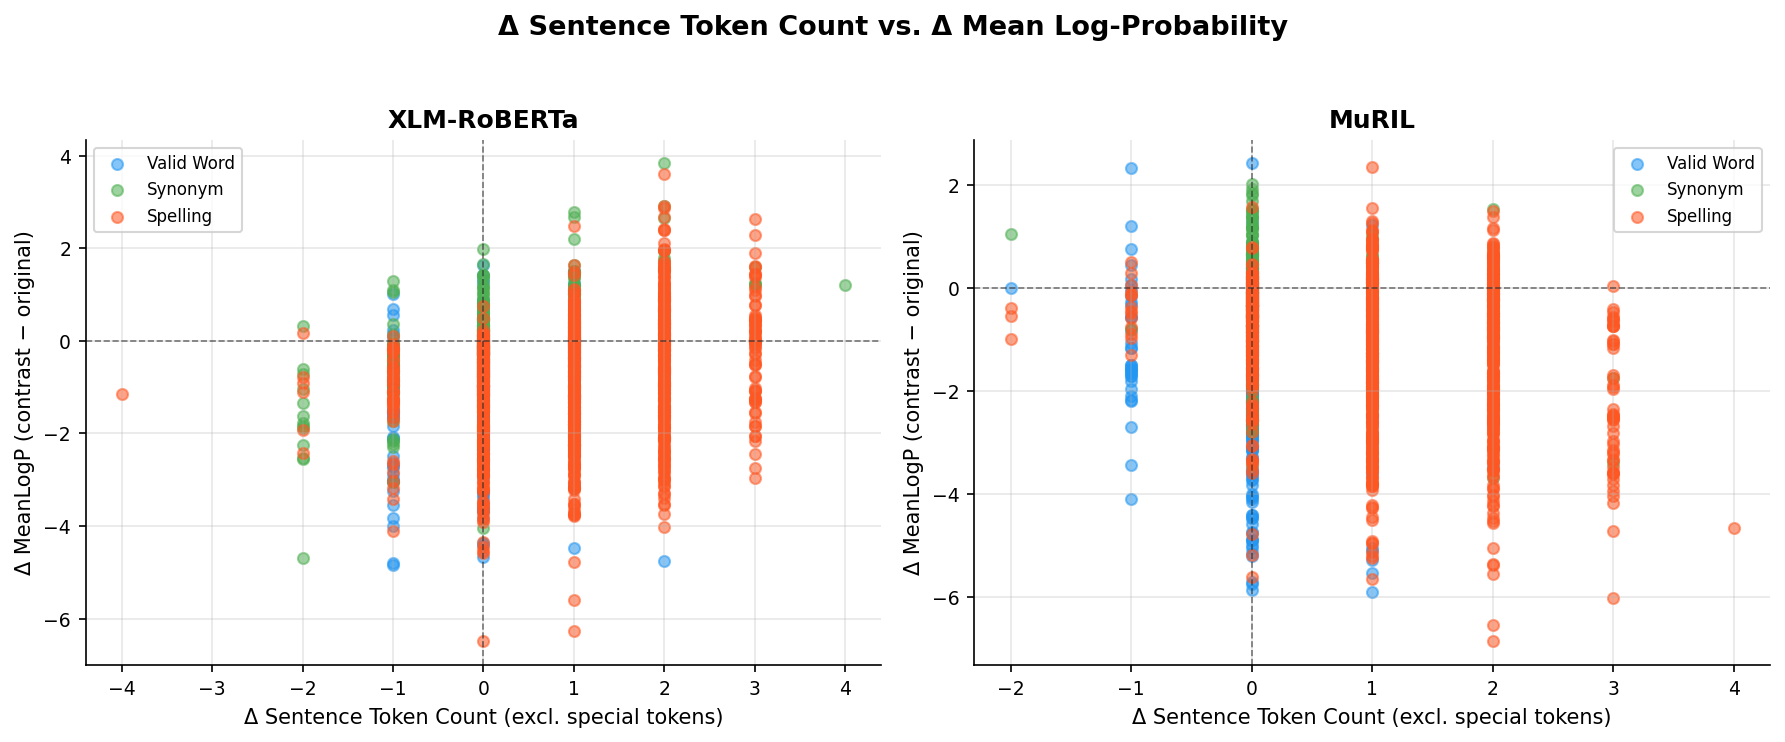

Figure 2: Sentence Token Length Changes vs. Plausibility Shifts


In [5]:
# Display Figure 2: Sentence Token Delta vs. MeanLogP Plausibility Shift
print("Figure 2: Sentence Token Length Changes vs. Plausibility Shifts")
display(Image(filename='results/runs/scaleup_rerun/figures/fig2_token_delta_vs_meanlp.png', width=750))


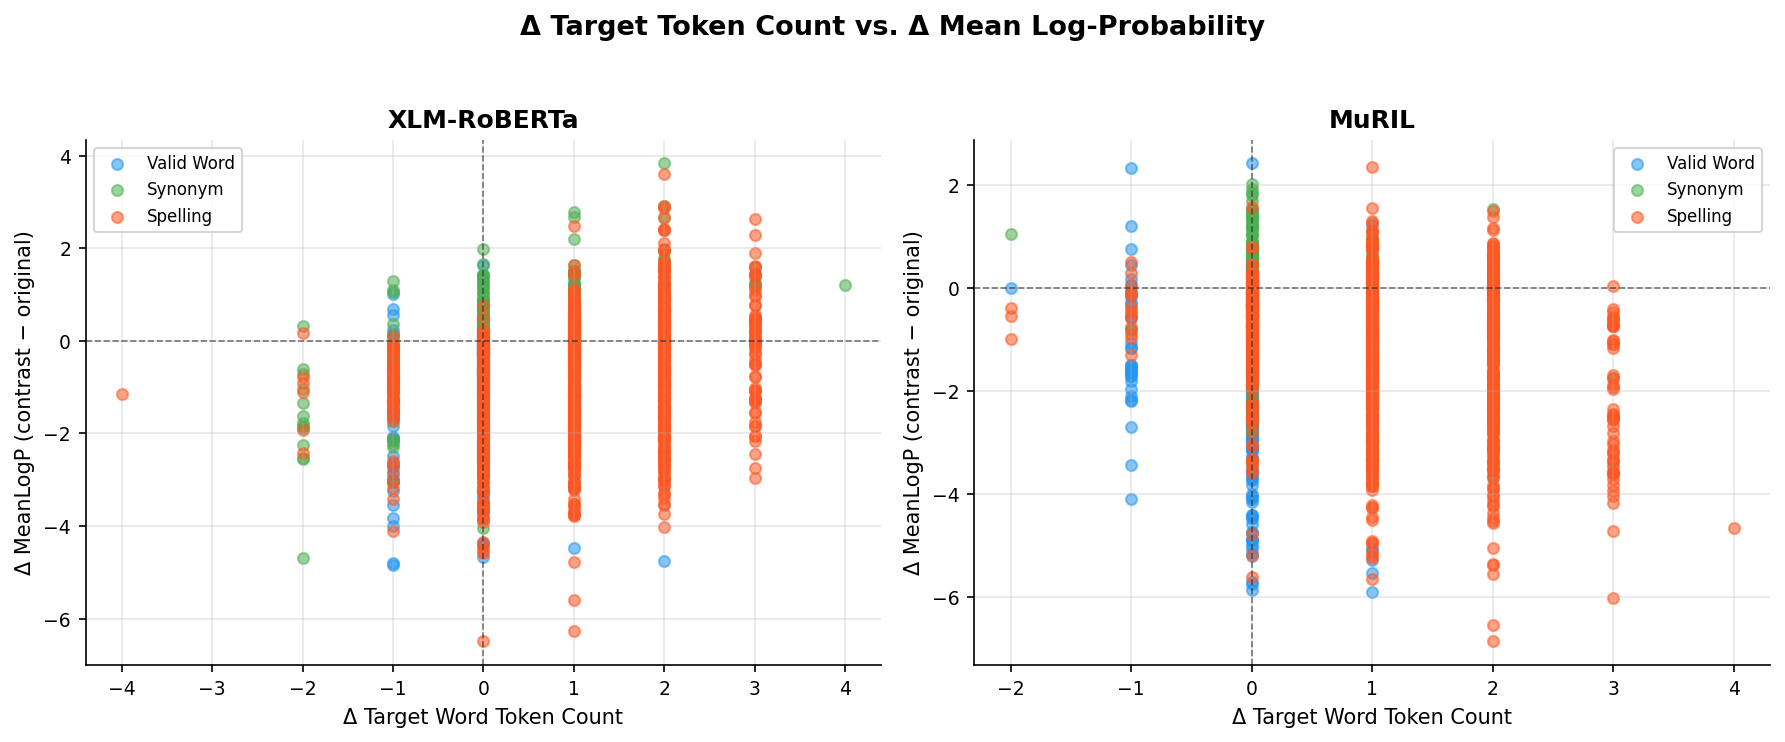

Figure 3: Target Subword Changes vs. Plausibility Shifts


In [6]:
# Display Figure 3: Target Token Delta vs. MeanLogP Plausibility Shift
print("Figure 3: Target Subword Changes vs. Plausibility Shifts")
display(Image(filename='results/runs/scaleup_rerun/figures/fig3_target_token_delta_vs_meanlp.png', width=750))


### 3.2 Key Tokenization Observations
1. **Catastrophic Fragmentation in Spelling Errors**:
   - In `REALISTIC_SPELLING_ERROR` ($N=1,005$), introducing authentic Devanagari spelling errors causes single-subword target coverage to collapse by **$-71.6\%$** in MuRIL ($91.7\% \to 20.1\%$) and by **$-55.9\%$** in XLM-RoBERTa ($62.3\% \to 6.4\%$).
   - This fragmentation induces an average sentence-level token inflation of **$+1.13$ subwords in MuRIL** and **$+1.04$ subwords in XLM-RoBERTa**, driven exclusively by target fracturing.
2. **Tokenizer Efficiency Advantage**:
   - Across all tracks, MuRIL's Indic-dedicated WordPiece vocabulary encodes Hindi sentences with **$7.9\%$ to $12.2\%$ fewer subwords** than XLM-RoBERTa's massively multilingual SentencePiece vocabulary.
3. **Subword Robustness on Synonyms**:
   - In `SYNONYM_SUBSTITUTION` ($N=362$), 98.6% of canonical targets tokenize into a single subword in MuRIL, and 92.8% remain single subwords after substitution (a modest $-5.8\%$ change).


## Section 4: Pseudo-Log-Likelihood (PLL) Scoring (RQ1 & RQ2)

### 4.1 Scoring Formulation
Bidirectional masked language models cannot directly compute joint sequence probabilities $P(W)$. Following Salazar et al. (2020), we compute the **Pseudo-Log-Likelihood (PLL)** via iterative masking:
$$\text{PLL}(W) = \sum_{t=1}^{|W|} \log P(w_t \mid W_{\setminus t}; \Theta)$$

To avoid length bias caused by token inflation, we apply length normalization:
$$\text{MeanLogP}(W) = \frac{\text{PLL}(W)}{|W_{\text{scorable}}|}$$

The signed plausibility shift is:
$$\Delta \text{MeanLogP} = \text{MeanLogP}(W_{\text{cont}}) - \text{MeanLogP}(W_{\text{orig}})$$
- $\Delta \text{MeanLogP} < 0$: The original sentence is preferred (canonical preference).
- $\Delta \text{MeanLogP} > 0$: The contrast sentence is preferred.


In [7]:
# Load descriptive statistics (Table 2)
desc_stats = pd.read_csv('results/runs/scaleup_rerun/analysis/descriptive_statistics.csv')

# Filter to scorable primary benchmark rows (include_rejected == True)
table2_df = desc_stats[desc_stats['include_rejected'] == True][[
    'model_name', 'track', 'n_pairs', 'delta_meanlp_mean', 'delta_meanlp_median',
    'delta_meanlp_std', 'delta_meanlp_iqr', 'delta_meanlp_min', 'delta_meanlp_max',
    'delta_meanlp_n_negative'
]].copy()

table2_df['pct_original_preferred'] = (table2_df['delta_meanlp_n_negative'] / table2_df['n_pairs'] * 100).round(1)

table2_df.columns = [
    'Model Checkpoint', 'Track Scope', 'N Pairs', 'Mean Δ MeanLogP', 'Median Δ',
    'SD', 'IQR', 'Min Δ', 'Max Δ', 'Original Preferred (N)', 'Original Preferred (%)'
]

print("=== TABLE 2: MODEL PLAUSIBILITY SHIFTS (N=1,679 PRIMARY PAIRS) ===")
display(table2_df)


,Model Checkpoint,Track Scope,N Pairs,Mean Δ MeanLogP,Median Δ,SD,IQR,Min Δ,Max Δ,Original Preferred (N),Original Preferred (%)
0,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,312,-1.0831,-0.9464,1.2195,1.4564,-4.8362,1.6353,258,82.7000
1,FacebookAI/xlm-roberta-base,SYNONYM_SUBSTITUTION,362,-0.0098,-0.0084,1.0110,0.9386,-4.6842,3.8360,183,50.6000
2,FacebookAI/xlm-roberta-base,REALISTIC_SPELLING_ERROR,1005,-0.8864,-0.7752,1.2929,1.6561,-6.4884,3.6106,768,76.4000
3,google/muril-base-cased,VALID_WORD_CONTEXT,312,-1.8470,-1.6755,1.3965,1.6648,-5.9067,2.4179,294,94.2000
4,google/muril-base-cased,SYNONYM_SUBSTITUTION,362,-0.1787,-0.1049,0.8545,0.8320,-3.6843,2.0094,213,58.8000
5,google/muril-base-cased,REALISTIC_SPELLING_ERROR,1005,-1.2045,-0.8892,1.3526,1.7256,-6.8610,2.3473,836,83.2000


=== TABLE 2: MODEL PLAUSIBILITY SHIFTS (N=1,679 PRIMARY PAIRS) ===


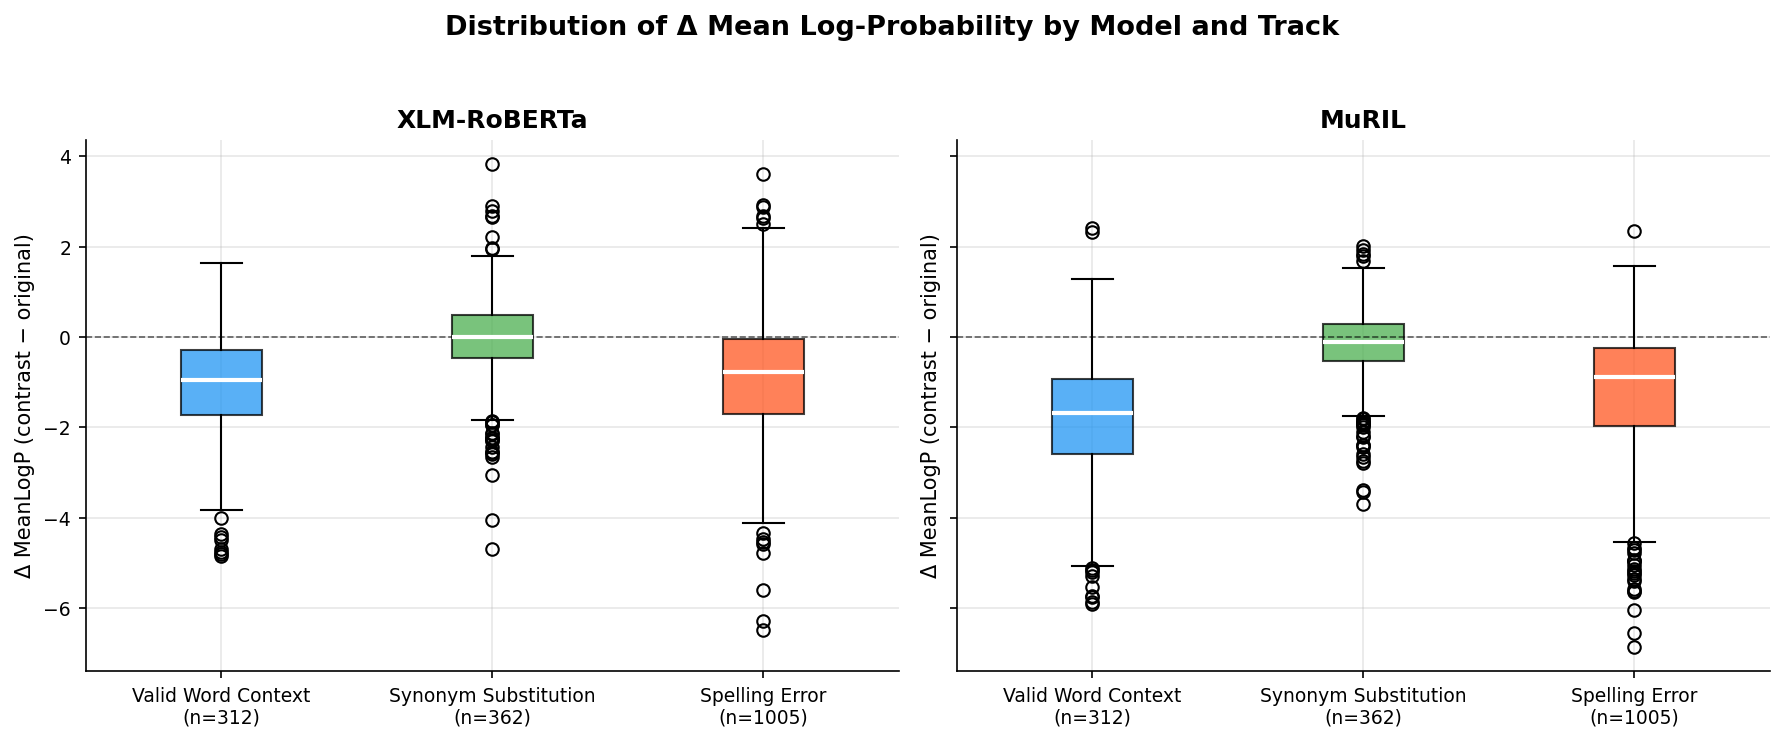

Figure 1: Distribution of Length-Normalized Pseudo-Log-Likelihood Deltas


In [8]:
# Display Figure 1: Plausibility Shifts by Track
print("Figure 1: Distribution of Length-Normalized Pseudo-Log-Likelihood Deltas")
display(Image(filename='results/runs/scaleup_rerun/figures/fig1_delta_meanlp_by_track.png', width=750))


### 4.2 Key Scoring Observations
1. **Harsher Spelling Penalties in MuRIL**:
   - In `REALISTIC_SPELLING_ERROR` ($N=1,005$), MuRIL penalizes spelling errors substantially more decisively than XLM-RoBERTa:
     - **MuRIL**: Original preferred in **$83.2\%$** of pairs (836/1,005); Mean $\Delta = -1.2045$, Median $= -0.8892$.
     - **XLM-RoBERTa**: Original preferred in **$76.4\%$** of pairs (768/1,005); Mean $\Delta = -0.8864$, Median $= -0.7752$.
2. **Contextual Sensitivity**:
   - Both models strongly reject contextual semantic mismatches (`VALID_WORD_CONTEXT`, $N=312$): MuRIL prefers the original in **$94.2\%$** of pairs (mean $\Delta = -1.8470$), while XLM-RoBERTa prefers the original in **$82.7\%$** (mean $\Delta = -1.0831$).
3. **Synonym Interchangeability**:
   - In `SYNONYM_SUBSTITUTION` ($N=362$), XLM-RoBERTa treats synonyms as near-interchangeable (mean $\Delta = -0.0098$, 50.6% preference). MuRIL displays a modest negative shift (mean $\Delta = -0.1787$, 58.8% preference), reflecting frequency distributions in its Indic training corpus.
4. **Non-Causal Guardrail**:
   - These plausibility deltas represent probabilistic language model scores under bidirectional conditioning, not direct causal claims about human grammatical acceptability.


## Section 5: Cross-Model Comparison (RQ2)

### 5.1 Measuring Concordance across Architectures
Because MuRIL and XLM-RoBERTa utilize entirely different subword vocabularies and tokenization algorithms, their raw PLL sums cannot be directly cross-compared. Cross-model concordance is evaluated using:
1. **Directional Sign Agreement**: Percentage of pairs where both models agree on the preference direction ($	ext{sgn}(\Delta_{\text{XLM}}) == \text{sgn}(\Delta_{\text{MuRIL}})$).
2. **Spearman Rank Correlation ($r_s$)**: Rank correlation of within-model signed deltas ($\Delta \text{MeanLogP}$), with Fisher $z$-transformed 95% confidence intervals.


In [9]:
# Load cross-model comparison results (Table 3)
model_comp = pd.read_csv('results/runs/scaleup_rerun/analysis/model_comparison.csv')

display_mc = model_comp[[
    'track_scope', 'n_pairs', 'direction_both_negative', 'direction_both_positive',
    'direction_xlm_neg_muril_pos', 'direction_xlm_pos_muril_neg',
    'direction_agreement_rate', 'spearman_r_delta_meanlp', 'p_value', 'ci_95_lo', 'ci_95_hi'
]].copy()

display_mc['direction_agreement_rate'] = (display_mc['direction_agreement_rate'] * 100).round(2)
display_mc['ci_95'] = display_mc.apply(lambda r: f"[{r['ci_95_lo']:.4f}, {r['ci_95_hi']:.4f}]", axis=1)

display_mc = display_mc.drop(columns=['ci_95_lo', 'ci_95_hi'])
display_mc.columns = [
    'Track Scope', 'N Pairs', 'Both Neg (Orig)', 'Both Pos (Cont)',
    'XLM Neg / MuRIL Pos', 'XLM Pos / MuRIL Neg', 'Agreement Rate (%)',
    'Spearman rs', 'p-value', '95% CI'
]

print("=== TABLE 3: CROSS-MODEL CONCORDANCE (N=1,679 PRIMARY PAIRS) ===")
display(display_mc)


,Track Scope,N Pairs,Both Neg (Orig),Both Pos (Cont),XLM Neg / MuRIL Pos,XLM Pos / MuRIL Neg,Agreement Rate (%),Spearman rs,p-value,95% CI
0,ALL_TRACKS,1679,1055,182,154,288,73.6700,0.5496,0.0000,"[0.5153, 0.5821]"
1,VALID_WORD_CONTEXT,312,252,12,6,42,84.6200,0.4590,0.0000,"[0.3666, 0.5424]"
2,SYNONYM_SUBSTITUTION,362,126,92,57,87,60.2200,0.2271,0.0000,"[0.1269, 0.3226]"
3,REALISTIC_SPELLING_ERROR,1005,677,78,91,159,75.1200,0.5513,0.0000,"[0.5067, 0.5929]"


=== TABLE 3: CROSS-MODEL CONCORDANCE (N=1,679 PRIMARY PAIRS) ===


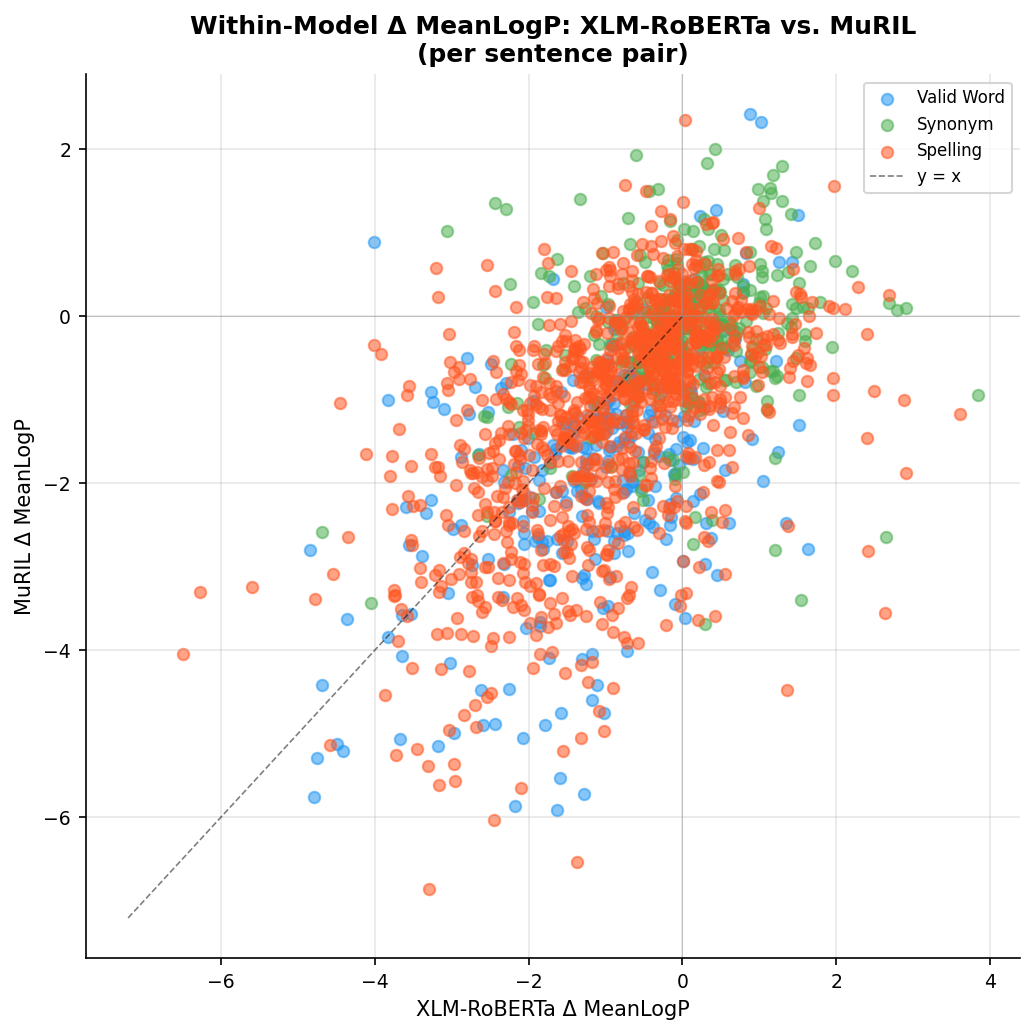

Figure 4: Cross-Model Scatter Plot of Delta MeanLogP


In [10]:
# Display Figure 4: Cross-Model Plausibility Scatter
print("Figure 4: Cross-Model Scatter Plot of Delta MeanLogP")
display(Image(filename='results/runs/scaleup_rerun/figures/fig4_model_comparison_scatter.png', width=750))


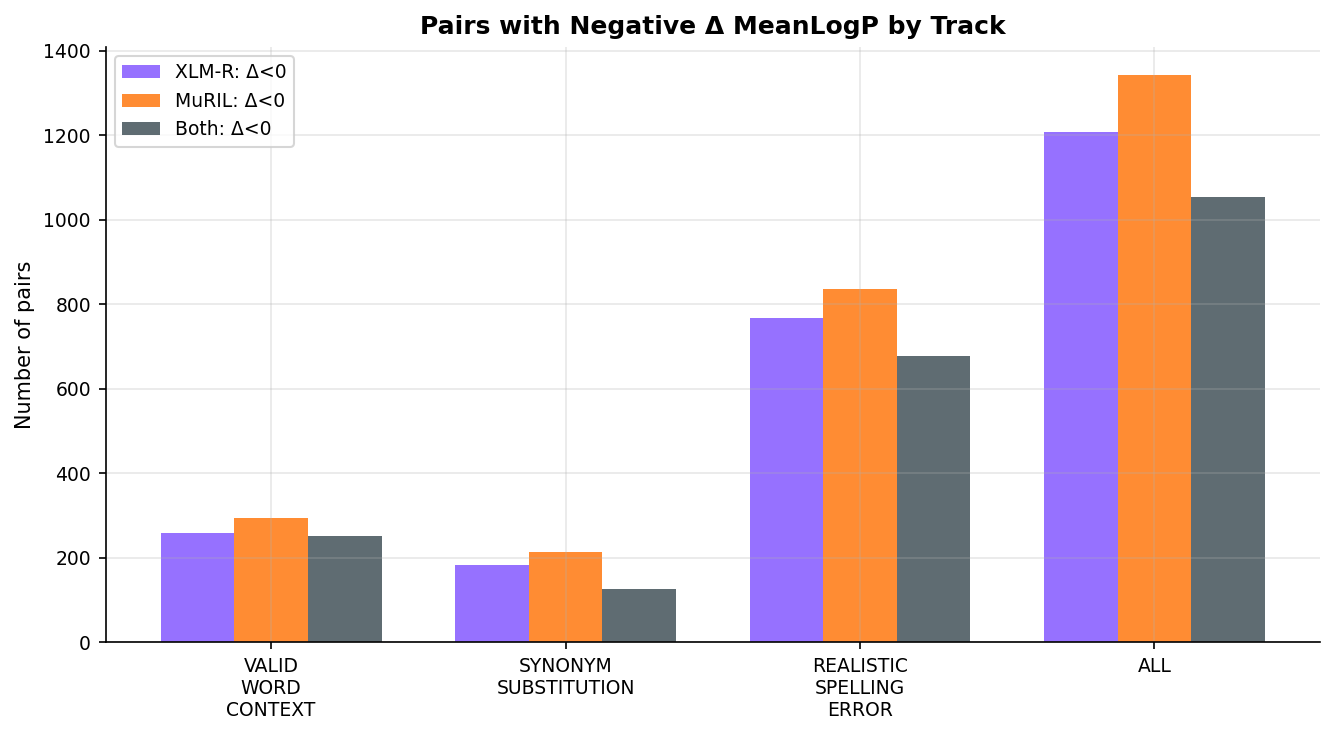

Figure 5: Directional Agreement Proportions Across Tracks


In [11]:
# Display Figure 5: Directional Agreement Proportions
print("Figure 5: Directional Agreement Proportions Across Tracks")
display(Image(filename='results/runs/scaleup_rerun/figures/fig5_direction_agreement.png', width=650))


### 5.2 Key Cross-Model Observations
1. **Global Concordance on Prominent Contrasts**:
   - Across all 1,679 pairs, the two architectures exhibit **$73.67\%$ directional agreement** and a statistically significant rank correlation of **$r_s = +0.5496$** ($p < 10^{-15}$, 95% CI $[0.5153, 0.5821]$).
   - Concordance is highest in `VALID_WORD_CONTEXT` ($84.62\%$ agreement, $r_s = +0.4590$) and `REALISTIC_SPELLING_ERROR` ($75.12\%$ agreement, $r_s = +0.5513$).
2. **Decoupling on Synonyms**:
   - In `SYNONYM_SUBSTITUTION` ($N=362$), directional agreement drops to **$60.22\%$** and rank correlation weakens to **$r_s = +0.2271$** ($p = 1.3 \times 10^{-5}$).
   - This indicates that when semantic truth conditions are preserved, the models' scoring preferences reflect independent pretraining corpus frequencies rather than shared linguistic structures.


## Section 6: Explanation Stability (RQ3)

### 6.1 The Stage 6 Masked-Target Artifact vs. Stage 7 Visible-Target Protocol
A critical methodological insight documented in this project is the **Masked-Target Artifact**:
- In early stability evaluations (Stage 6), the target word was masked with `[MASK]` in both original and contrast sentences.
- Because spelling perturbations resided exclusively inside the target word, masking the target caused both input sequences to become byte-identical ($X_{\text{orig}} \equiv X_{\text{cont}}$).
- This generated an illusory, trivial stability score of $\rho = 1.0000$ and $\text{Cosine} = 1.0000$ with zero variance.

To resolve this artifact, we formulated the **Visible-Target Scoring Protocol** in Stage 7:
1. Target words remain **fully visible** in the input text during attribution computation.
2. The target prediction score is defined as the mean unnormalized logit of the actual target subwords:
   $$S(X; Y_{\text{target}}) = \frac{1}{|T|} \sum_{j \in T} \text{Logit}(p_j, y_j)$$
3. Attributions are computed across aligned context tokens while the model processes the actual spelling error.


In [12]:
# Load explanation stability summary (Table 4)
stab_summary = pd.read_csv('results/runs/scaleup_rerun/dashboard_data/stability_summary.csv')

display_stab = stab_summary[[
    'model_name', 'method', 'subset', 'pair_count',
    'stage6_masked_target_stability_rho', 'stage6_masked_target_cosine',
    'visible_target_stability_rho_mean', 'visible_target_stability_rho_median',
    'visible_target_cosine_mean', 'visible_target_cosine_median'
]].copy()

display_stab.columns = [
    'Model Checkpoint', 'Method', 'Subset', 'Pair Count (N)',
    'Stage 6 Masked ρ', 'Stage 6 Masked Cosine',
    'Visible Mean ρ', 'Visible Median ρ',
    'Visible Mean Cosine', 'Visible Median Cosine'
]

print("=== TABLE 4: VISIBLE-TARGET EXPLANATION STABILITY (N=1,005 SPELLING PAIRS) ===")
display(display_stab)


,Model Checkpoint,Method,Subset,Pair Count (N),Stage 6 Masked ρ,Stage 6 Masked Cosine,Visible Mean ρ,Visible Median ρ,Visible Mean Cosine,Visible Median Cosine
0,FacebookAI/xlm-roberta-base,attention,all_scorable_pooled,1005,1.0000,1.0000,0.6258,0.7333,0.9353,0.9550
1,FacebookAI/xlm-roberta-base,attention,strict_single_subword,52,1.0000,1.0000,0.6306,0.7746,0.9349,0.9598
2,FacebookAI/xlm-roberta-base,attention,multi_subword_remainder,953,1.0000,1.0000,0.6255,0.7333,0.9353,0.9548
3,FacebookAI/xlm-roberta-base,integrated_gradients,all_scorable_pooled,1005,1.0000,1.0000,0.3319,0.4000,0.8890,0.9204
4,FacebookAI/xlm-roberta-base,integrated_gradients,strict_single_subword,52,1.0000,1.0000,0.4210,0.5442,0.9026,0.9313
5,FacebookAI/xlm-roberta-base,integrated_gradients,multi_subword_remainder,953,1.0000,1.0000,0.3270,0.3929,0.8883,0.9199
6,google/muril-base-cased,attention,all_scorable_pooled,1005,1.0000,1.0000,0.8027,0.8857,0.9518,0.9733
7,google/muril-base-cased,attention,strict_single_subword,197,1.0000,1.0000,0.8053,0.9000,0.9725,0.9861
8,google/muril-base-cased,attention,multi_subword_remainder,808,1.0000,1.0000,0.8021,0.8857,0.9468,0.9686
9,google/muril-base-cased,integrated_gradients,all_scorable_pooled,1005,1.0000,1.0000,0.2560,0.3000,0.9818,0.9867


=== TABLE 4: VISIBLE-TARGET EXPLANATION STABILITY (N=1,005 SPELLING PAIRS) ===


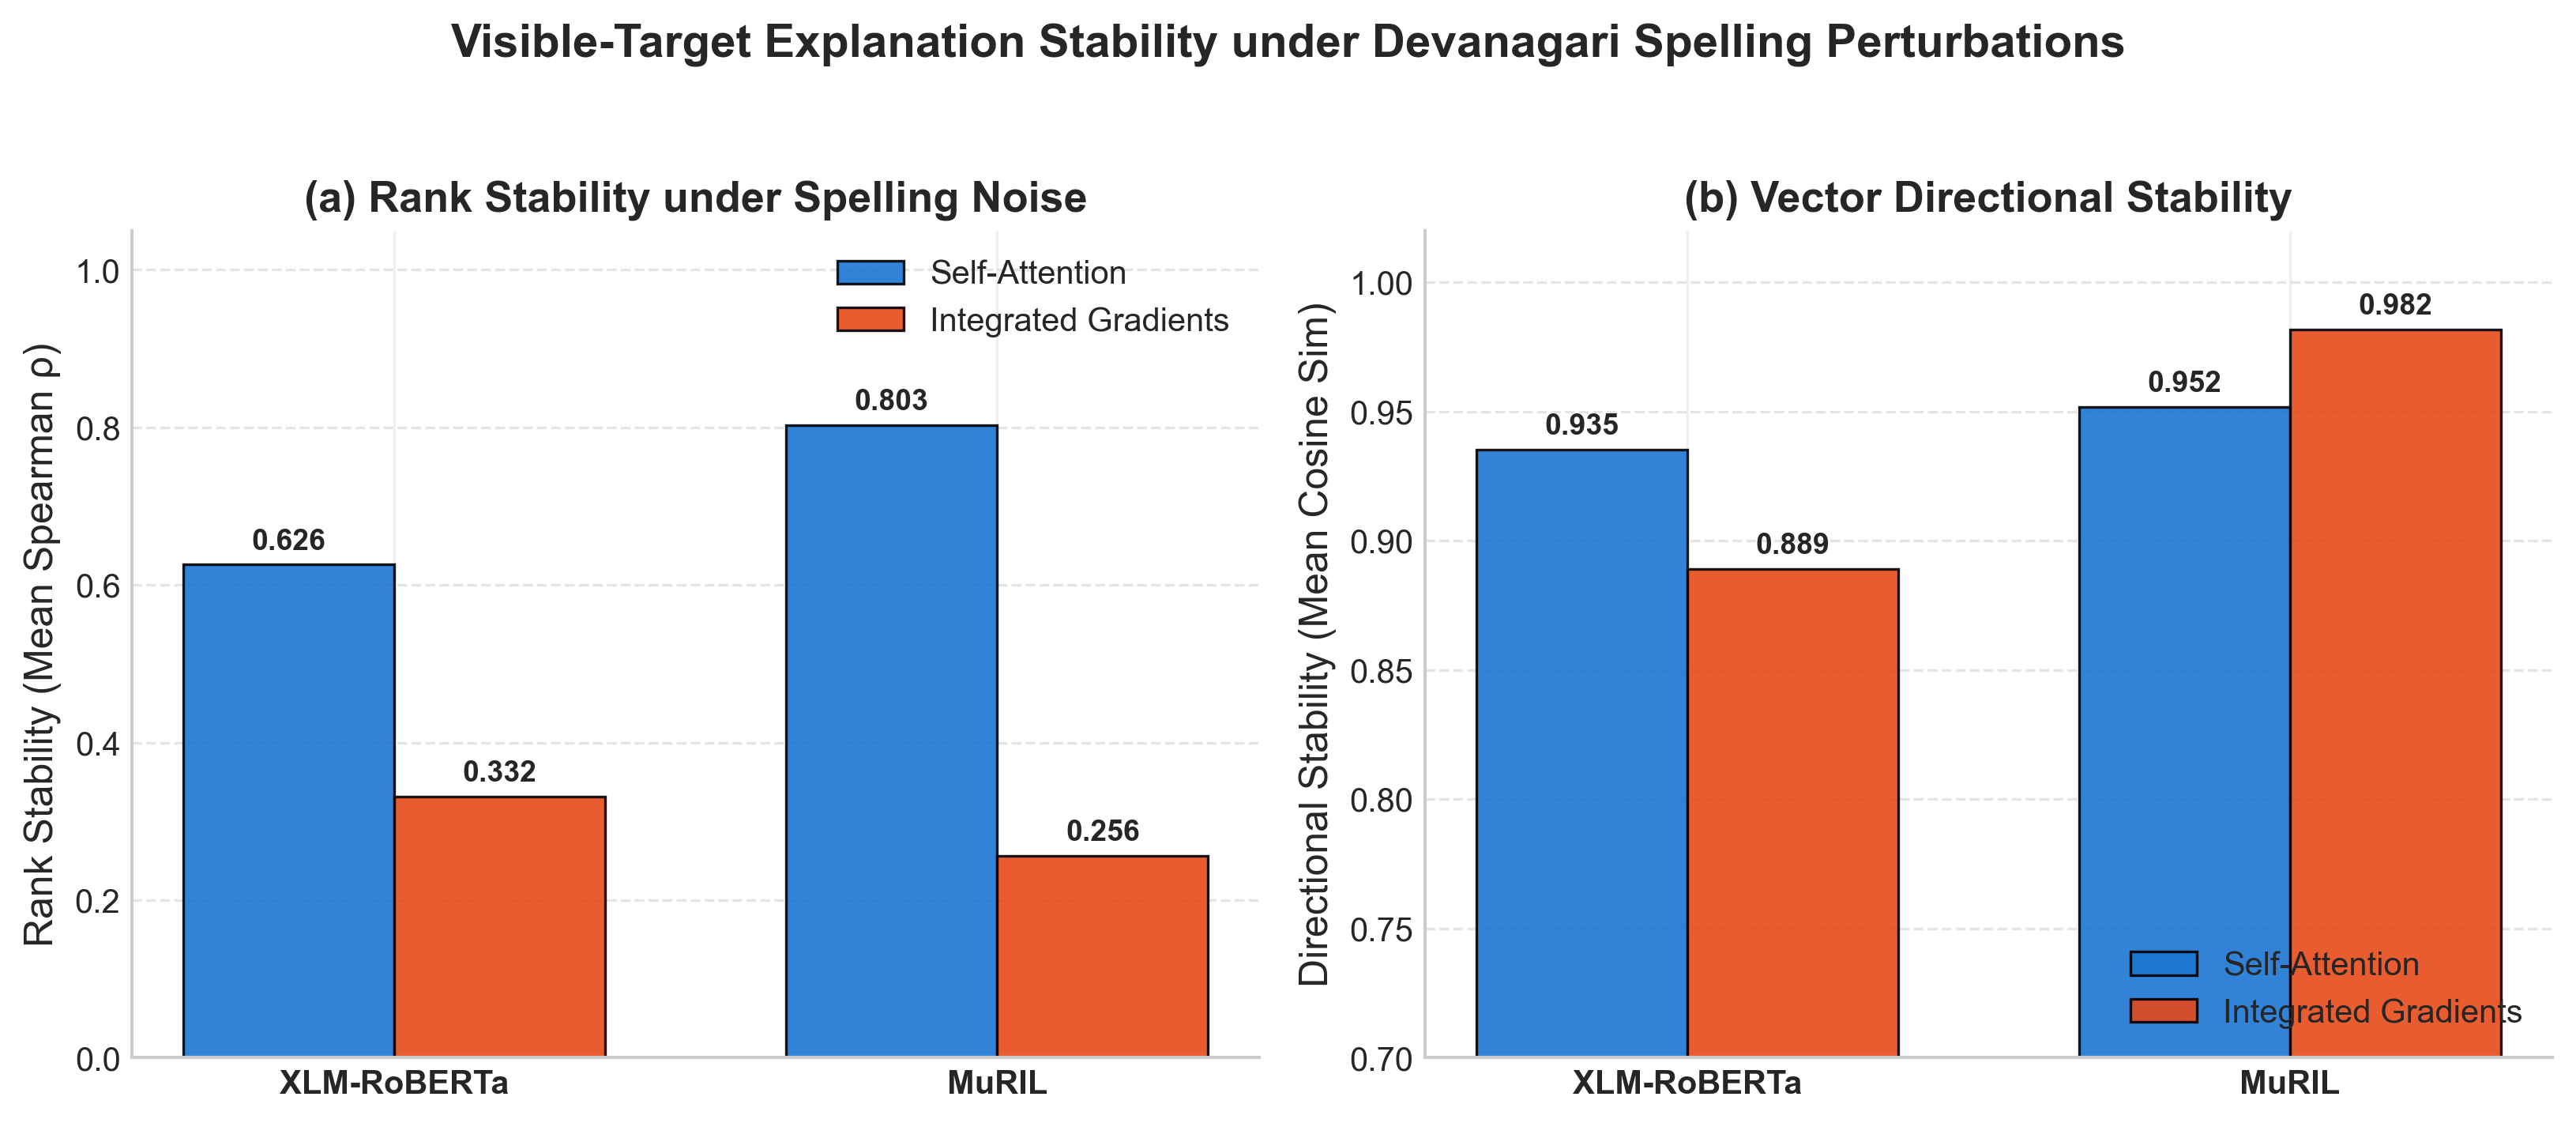

Figure 6: Visible-Target Explanation Stability under Devanagari Spelling Noise


In [13]:
# Display Figure 6: Explanation Stability Comparison
print("Figure 6: Visible-Target Explanation Stability under Devanagari Spelling Noise")
display(Image(filename='results/runs/scaleup_rerun/figures/fig6_explanation_stability.png', width=800))


### 6.2 Key Stability Observations
1. **Attention Rank Stability Superiority**:
   - Under authentic spelling noise, last-layer multi-head self-attention achieves **$1.9\times$ to $3.1\times$ higher rank stability** than Integrated Gradients:
     - **MuRIL**: Pooled Mean $\rho = 0.8027$ (Attention) vs. $0.2560$ (IG).
     - **XLM-RoBERTa**: Pooled Mean $\rho = 0.6258$ (Attention) vs. $0.3319$ (IG).
2. **Dissociation between Rank and Vector Stability in IG**:
   - While Integrated Gradients exhibits low rank stability ($ho \approx 0.26\text{--}0.33$), its **Cosine Similarity remains exceptionally high** ($0.8890$ to $0.9818$).
   - **Geometric Interpretation**: The gradient attribution vector preserves its global orientation in high-dimensional embedding space, but the relative ranking of individual context tokens fluctuates under localized orthographic noise.


## Section 7: Faithfulness and Context Erasure (RQ4)

### 7.1 Causal Feature Erasure Protocol
Following the ERASER benchmark (DeYoung et al., 2020), explanation faithfulness is evaluated by measuring model score degradation when attributed context tokens are erased.

For each sentence ($N=2,010$ sentences per model across 1,005 spelling pairs), context tokens are ranked by attribution score. We evaluate three masking interventions at fractions $f \in \{0.10, 0.20, 0.30\}$:
- **Top-$k$ Erasure**: Masking the top $k = \lceil f \cdot |C| \rceil$ tokens with `[MASK]`.
- **Bottom-$k$ Erasure (Control)**: Masking the $k$ lowest-attributed tokens.
- **Random-$k$ Erasure**: Masking $k$ random tokens (averaged over 5 independent trials).

We evaluate:
1. **Faithfulness Gap**: $\Delta S_{\text{top}} - \Delta S_{\text{bottom}} = S_{\text{bottom}} - S_{\text{top}}$ (positive indicates that top tokens degrade target logit more than control tokens).
2. **Win Rate vs. Bottom Control**: Percentage of sentences where $\Delta S_{\text{top}} > \Delta S_{\text{bottom}}$.


In [14]:
# Load faithfulness summary (Table 5)
faith_summary = pd.read_csv('results/runs/scaleup_rerun/dashboard_data/faithfulness_summary.csv')

display_faith = faith_summary[[
    'model_name', 'method', 'subset', 'fraction', 'n_evaluated_sentences',
    'top_k_logit_drop_mean', 'bottom_k_logit_drop_mean', 'random_k_logit_drop_mean',
    'faithfulness_gap_mean', 'faithfulness_gap_median',
    'win_rate_vs_bottom', 'win_rate_vs_random'
]].copy()

display_faith['win_rate_vs_bottom'] = (display_faith['win_rate_vs_bottom'] * 100).round(2)
display_faith['win_rate_vs_random'] = (display_faith['win_rate_vs_random'] * 100).round(2)

display_faith.columns = [
    'Model Checkpoint', 'Method', 'Subset', 'Fraction (f)', 'N Sentences',
    'Mean Top Drop', 'Mean Bottom Drop', 'Mean Random Drop',
    'Mean Faith Gap', 'Median Faith Gap',
    'Win Rate vs Bottom (%)', 'Win Rate vs Random (%)'
]

print("=== TABLE 5: FAITHFULNESS UNDER CONTEXT ERASURE (N=2,010 SENTENCES / MODEL) ===")
display(display_faith)


,Model Checkpoint,Method,Subset,Fraction (f),N Sentences,Mean Top Drop,Mean Bottom Drop,Mean Random Drop,Mean Faith Gap,Median Faith Gap,Win Rate vs Bottom (%),Win Rate vs Random (%)
0,FacebookAI/xlm-roberta-base,attention,all_scorable,0.1000,2010,-6.2969,-8.7344,-7.8968,2.4374,1.6813,63.5300,52.4900
1,FacebookAI/xlm-roberta-base,attention,all_scorable,0.2000,2010,-6.2915,-9.0881,-8.3099,2.7966,2.2942,65.7700,55.9200
2,FacebookAI/xlm-roberta-base,attention,all_scorable,0.3000,2010,-4.4711,-8.2846,-6.6174,3.8134,3.0413,67.4600,57.4600
3,FacebookAI/xlm-roberta-base,attention,strict_single_subword,0.1000,104,-2.1218,-4.8635,-4.3861,2.7417,2.3571,69.2300,58.6500
4,FacebookAI/xlm-roberta-base,attention,strict_single_subword,0.2000,104,-1.5806,-5.1870,-3.9164,3.6064,2.4584,69.2300,54.8100
5,FacebookAI/xlm-roberta-base,attention,strict_single_subword,0.3000,104,0.2633,-2.9888,-1.8542,3.2521,1.9329,59.6200,55.7700
6,FacebookAI/xlm-roberta-base,integrated_gradients,all_scorable,0.1000,2010,-6.9950,-8.9797,-7.8777,1.9847,1.1131,59.7500,47.5100
7,FacebookAI/xlm-roberta-base,integrated_gradients,all_scorable,0.2000,2010,-7.0120,-9.2597,-8.0825,2.2477,1.5954,62.2400,51.4400
8,FacebookAI/xlm-roberta-base,integrated_gradients,all_scorable,0.3000,2010,-4.7837,-8.1795,-6.7426,3.3957,2.6586,65.1200,57.7100
9,FacebookAI/xlm-roberta-base,integrated_gradients,strict_single_subword,0.1000,104,-3.3843,-5.0790,-4.0995,1.6947,0.4560,54.8100,49.0400


=== TABLE 5: FAITHFULNESS UNDER CONTEXT ERASURE (N=2,010 SENTENCES / MODEL) ===


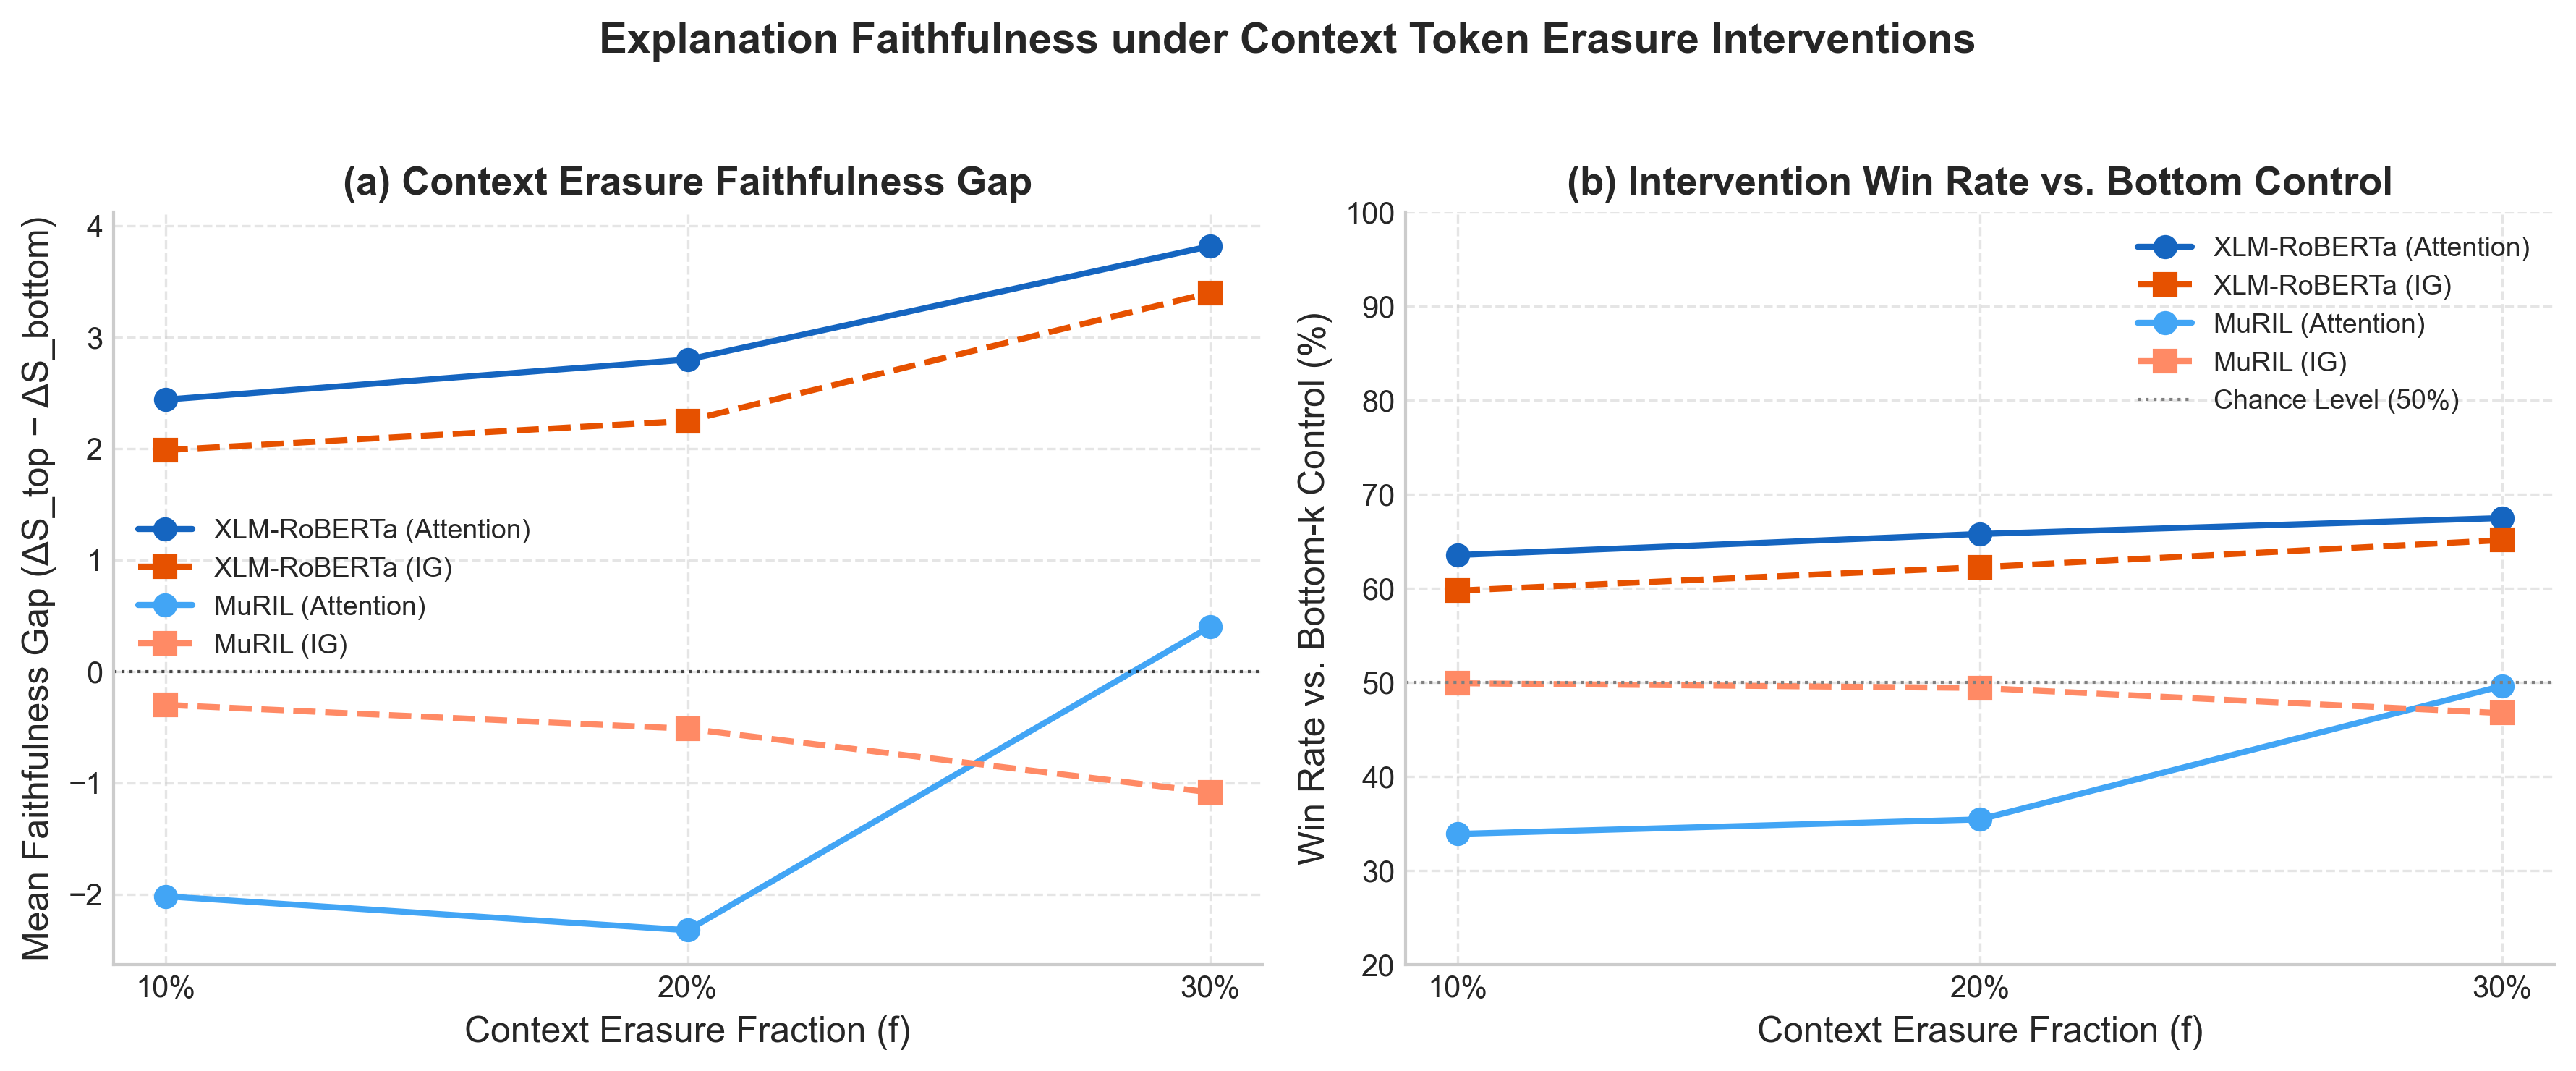

Figure 7: Context Erasure Faithfulness across Intervention Fractions


In [15]:
# Display Figure 7: Faithfulness Interventions Trajectory
print("Figure 7: Context Erasure Faithfulness across Intervention Fractions")
display(Image(filename='results/runs/scaleup_rerun/figures/fig7_faithfulness_interventions.png', width=800))


### 7.2 Key Faithfulness Observations
1. **Attention Outperforms Integrated Gradients in XLM-RoBERTa**:
   - In discrete masking tests on XLM-RoBERTa, self-attention attributions consistently achieve positive Faithfulness Gaps ($+2.44$ to $+3.81$) and win rates of **$63.53\%\text{--}67.46\%$** against bottom control erasure.
2. **Integrated Gradients Operates Near or Below Chance in MuRIL**:
   - In MuRIL, Integrated Gradients achieves win rates of only **$46.72\%\text{--}49.90\%$** (worse than or equal to random chance), yielding negative mean faithfulness gaps across all fractions ($-0.30$ to $-1.08$).
3. **Continuous Path Integrals vs. Discrete MLM Heads**:
   - **Theoretical Explanation**: Integrated Gradients accumulates gradients along a continuous straight-line path in embedding space:
     $$\gamma(\alpha) = x' + \alpha(x - x'), \quad \alpha \in [0, 1]$$
     This path traverses off-manifold embedding regions. In contrast, discrete token erasure in MLMs creates an abrupt contextual shift that aligns more closely with last-layer attention routing mechanisms.


## Section 8: Stability–Faithfulness Relationship (RQ5)

### 8.1 Evaluating the Relationship Between Stability and Faithfulness
A pervasive assumption in explainable AI is that attribution stability is an indicator of explanation quality—i.e., that a stable explanation is more likely to be faithful to the underlying model reasoning.

We test this hypothesis across all 1,005 Devanagari spelling pairs by correlating visible-target stability (Spearman $\rho$) with the mean faithfulness gap at $f=0.20$.


In [16]:
# Compute and display Table 6: Stability vs. Faithfulness Correlation Matrix
rel_df = pd.read_csv('results/runs/scaleup_rerun/dashboard_data/stability_faithfulness_relationship.csv')

corr_rows = []
for model in ['FacebookAI/xlm-roberta-base', 'google/muril-base-cased']:
    for method in ['attention', 'integrated_gradients']:
        for subset in ['all_scorable', 'strict_single_subword']:
            sub = rel_df[(rel_df['model_name'] == model) & (rel_df['method'] == method) & (rel_df['subset'] == subset)]
            valid = sub.dropna(subset=['visible_target_stability_rho', 'mean_faithfulness_gap_f20'])
            
            if len(valid) > 2:
                sp_r, sp_p = stats.spearmanr(valid['visible_target_stability_rho'], valid['mean_faithfulness_gap_f20'])
                pe_r, pe_p = stats.pearsonr(valid['visible_target_stability_rho'], valid['mean_faithfulness_gap_f20'])
                
                # Statistical interpretation
                if sp_p <= 0.05 and sp_r < 0:
                    interp = f"Weak Inverse Rank (rs={sp_r:.4f}, p={sp_p:.4f})"
                elif pe_p <= 0.05 and pe_r < 0:
                    interp = f"Weak Inverse Linear (r={pe_r:.4f}, p={pe_p:.4f})"
                elif pe_p <= 0.05 and pe_r > 0:
                    interp = f"Weak Positive Linear (r={pe_r:.4f}, p={pe_p:.4f})"
                elif sp_p <= 0.05 and sp_r > 0:
                    interp = f"Significant Positive Rank (rs={sp_r:.4f}, p={sp_p:.4f})"
                else:
                    interp = "Non-Significant (p > 0.05)"
                
                corr_rows.append({
                    'Model Checkpoint': model,
                    'Explanation Method': method,
                    'Evaluated Subset': subset,
                    'Sample Size (N)': len(valid),
                    'Spearman Rank rs': round(sp_r, 4),
                    'p-value (rs)': round(sp_p, 4),
                    'Pearson Linear r': round(pe_r, 4),
                    'p-value (r)': round(pe_p, 4),
                    'Empirical Interpretation': interp
                })

table6_df = pd.DataFrame(corr_rows)
print("=== TABLE 6: CORRELATION BETWEEN STABILITY AND FAITHFULNESS (N=1,005 SPELLING PAIRS) ===")
display(table6_df)


,Model Checkpoint,Explanation Method,Evaluated Subset,Sample Size (N),Spearman Rank rs,p-value (rs),Pearson Linear r,p-value (r),Empirical Interpretation
0,FacebookAI/xlm-roberta-base,attention,all_scorable,953,0.0607,0.0612,0.0564,0.0816,Non-Significant (p > 0.05)
1,FacebookAI/xlm-roberta-base,attention,strict_single_subword,52,0.2472,0.0773,0.2949,0.0338,"Weak Positive Linear (r=0.2949, p=0.0338)"
2,FacebookAI/xlm-roberta-base,integrated_gradients,all_scorable,953,0.0632,0.0510,0.0495,0.1270,Non-Significant (p > 0.05)
3,FacebookAI/xlm-roberta-base,integrated_gradients,strict_single_subword,52,0.1647,0.2434,0.1464,0.3005,Non-Significant (p > 0.05)
4,google/muril-base-cased,attention,all_scorable,808,-0.0442,0.2099,-0.0790,0.0248,"Weak Inverse Linear (r=-0.0790, p=0.0248)"
5,google/muril-base-cased,attention,strict_single_subword,197,-0.1924,0.0067,-0.1129,0.1141,"Weak Inverse Rank (rs=-0.1924, p=0.0067)"
6,google/muril-base-cased,integrated_gradients,all_scorable,808,0.0214,0.5442,0.0290,0.4108,Non-Significant (p > 0.05)
7,google/muril-base-cased,integrated_gradients,strict_single_subword,197,0.0344,0.6316,-0.0037,0.9592,Non-Significant (p > 0.05)


=== TABLE 6: CORRELATION BETWEEN STABILITY AND FAITHFULNESS (N=1,005 SPELLING PAIRS) ===


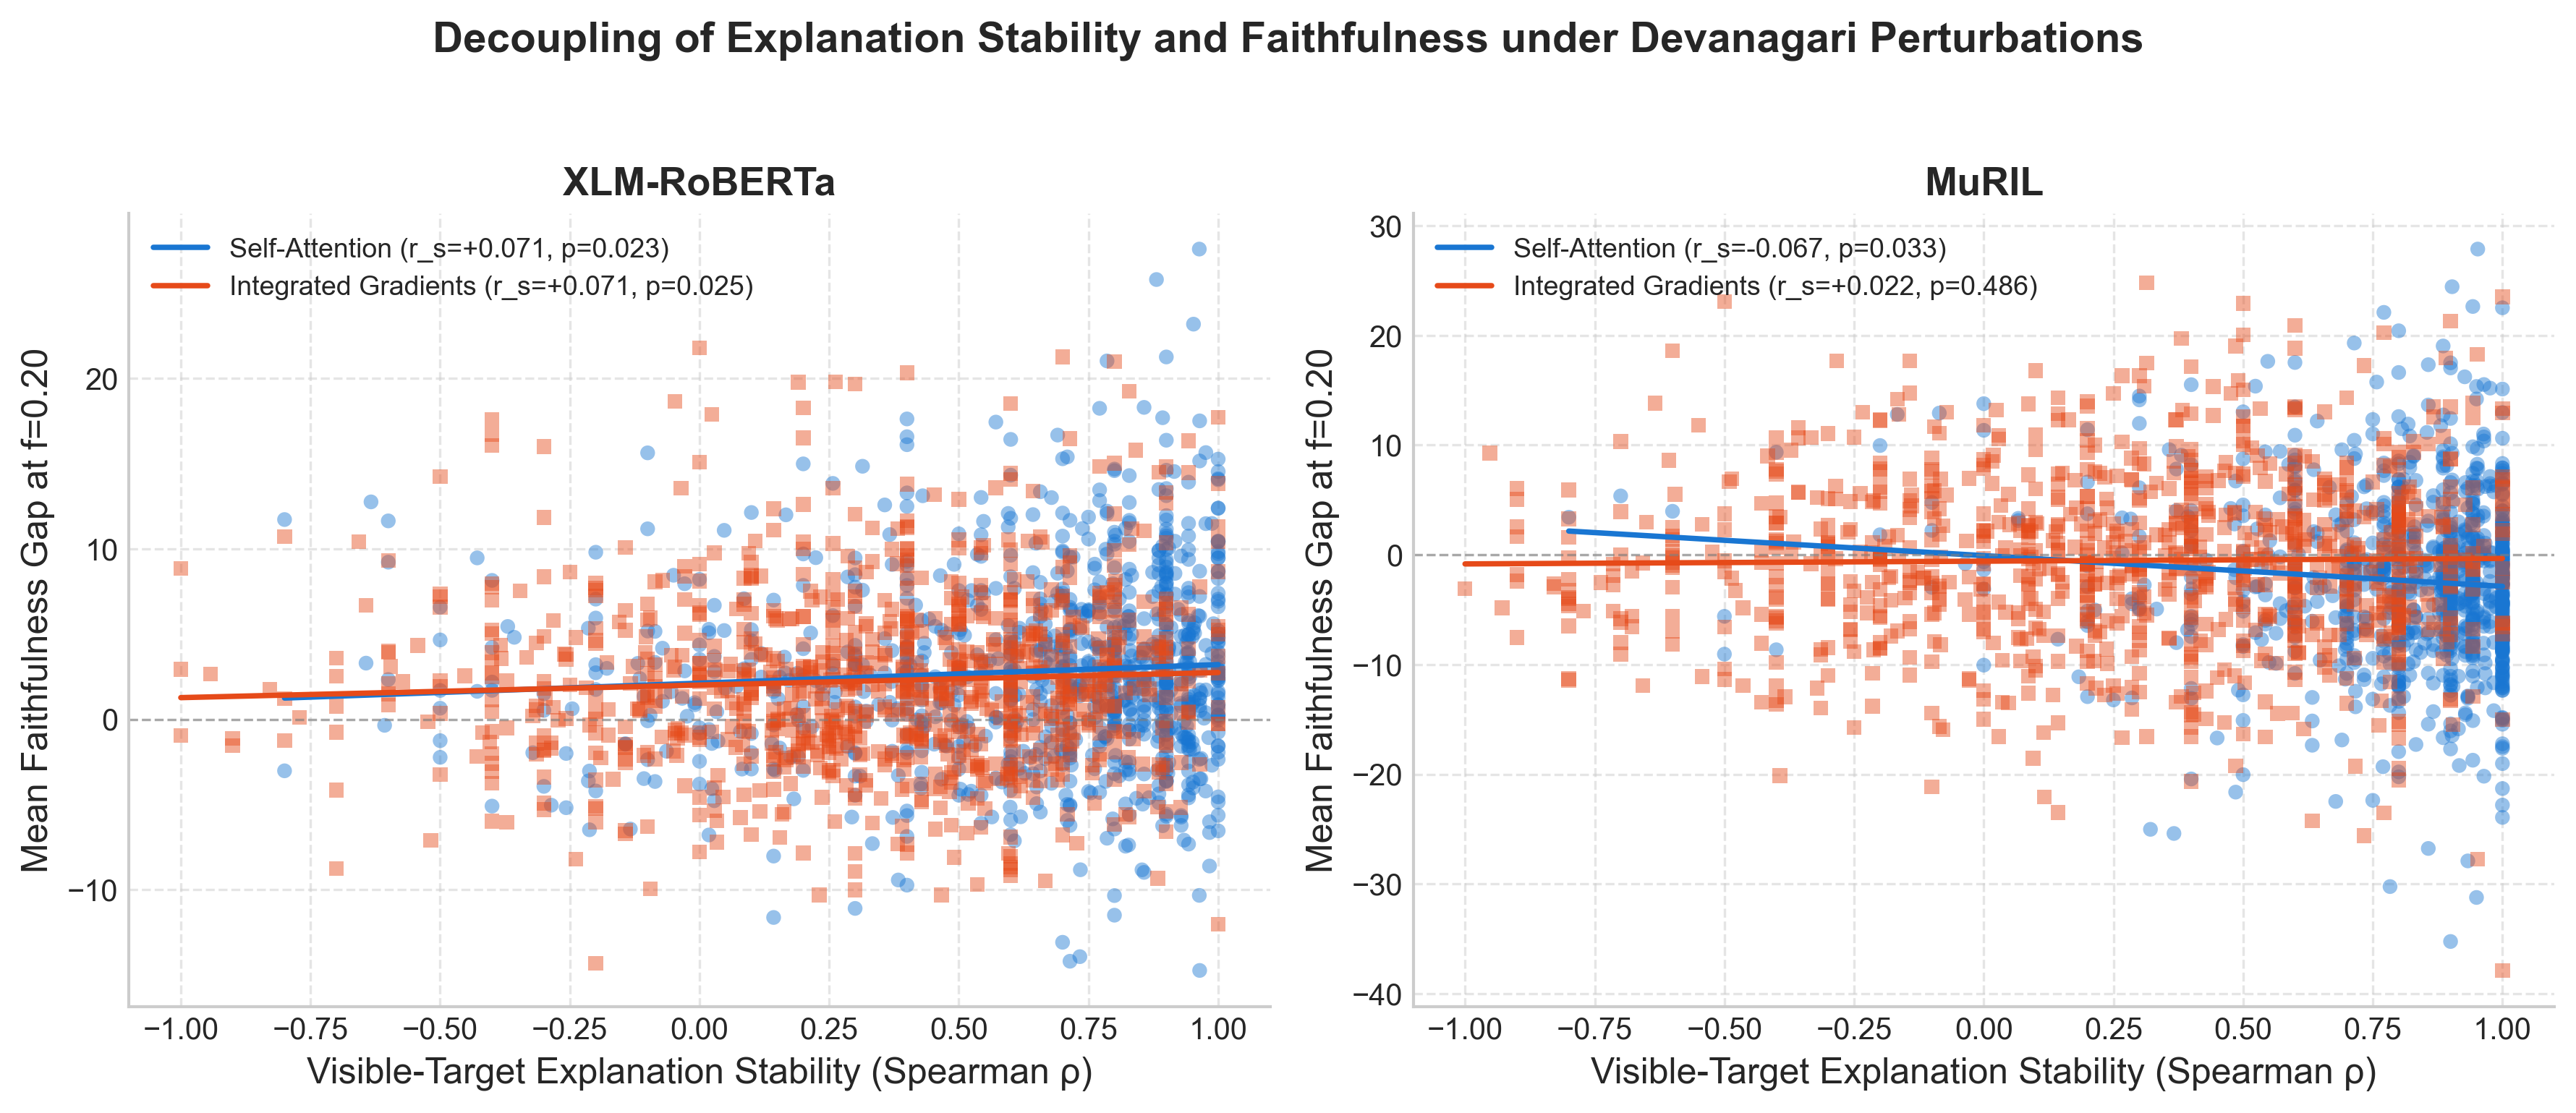

Figure 8: Visible-Target Stability vs. Faithfulness Decoupling


In [17]:
# Display Figure 8: Stability vs. Faithfulness Decoupling Scatter
print("Figure 8: Visible-Target Stability vs. Faithfulness Decoupling")
display(Image(filename='results/runs/scaleup_rerun/figures/fig8_stability_vs_faithfulness.png', width=800))


### 8.2 Statistical Interpretation & Core Conclusion
1. **Absence of a Consistent Positive Association**:
   - In the preliminary pilot ($N=20$), the absence of correlation was preliminary and limited by sample size. In this expanded scale-up benchmark ($N=953$ and $N=808$ scorable pairs), we evaluate stability–faithfulness relationships with substantially greater statistical resolution.
   - Importantly, **not all stability–faithfulness correlations are non-significant**:
     - **MuRIL Attention (Pooled, $N=808$)**: Pearson linear correlation is weakly negative and statistically significant ($r = -0.0790, p = 0.0248$), while Spearman rank correlation is non-significant ($r_s = -0.0442, p = 0.2099$).
     - **MuRIL Attention (Strict Single-Subword, $N=197$)**: Spearman rank correlation is weakly negative and statistically significant ($r_s = -0.1924, p = 0.0067$), while Pearson linear correlation is $r = -0.1129, p = 0.1141$.
     - **XLM-RoBERTa Attention (Strict Single-Subword, $N=52$)**: Pearson linear correlation is weakly positive ($r = +0.2949, p = 0.0338$), while Spearman rank correlation remains non-significant ($r_s = +0.2472, p = 0.0773$).
     - **Other Conditions**: XLM-RoBERTa Attention pooled ($r_s = +0.0607, p = 0.0612$), XLM-RoBERTa IG pooled ($r_s = +0.0632, p = 0.0510$), XLM-RoBERTa IG strict ($r_s = +0.1647, p = 0.2434$), MuRIL IG pooled ($r_s = +0.0214, p = 0.5442$), and MuRIL IG strict ($r_s = +0.0344, p = 0.6316$) all exhibit non-significant associations ($p > 0.05$).
2. **Proper Scientific Nuance**:
   - The appropriate overall conclusion is that **there is no consistent positive association between explanation stability and faithfulness**.
   - Some weak negative associations occur for MuRIL Attention, while other combinations are non-significant.
   - We do not claim that these empirical findings prove mathematical independence, establish causation, or rule out all sample-size limitations across all neural network architectures. Rather, within these evaluated models and benchmark, **stability to spelling perturbations cannot serve as a reliable empirical proxy for causal explanation faithfulness**.


## Section 9: Template Sensitivity Analysis

### 9.1 Purpose of the Template Benchmark ($N=1,957$)
To verify that our empirical findings are not idiosyncratic artifacts of specific sentence contexts, we evaluated the Secondary Template Sensitivity Benchmark ($N=1,957$ minimal pairs across 278 template frames).

> **Pedagogical Reminder**: The template sensitivity benchmark contains the primary pairs plus template-generated sentence frames. It evaluates frame invariance and is analyzed separately from the primary benchmark.


In [18]:
# Load Template Sensitivity descriptive statistics and model comparison
tmpl_desc = pd.read_csv('results/runs/scaleup_rerun/template_sensitivity/analysis/descriptive_statistics.csv')
tmpl_comp = pd.read_csv('results/runs/scaleup_rerun/template_sensitivity/analysis/model_comparison.csv')

# Format descriptive table
tmpl_desc_display = tmpl_desc[tmpl_desc['include_rejected'] == True][[
    'model_name', 'track', 'n_pairs', 'delta_meanlp_mean', 'delta_meanlp_median',
    'delta_meanlp_std', 'delta_meanlp_n_negative'
]].copy()
tmpl_desc_display['pct_orig_preferred'] = (tmpl_desc_display['delta_meanlp_n_negative'] / tmpl_desc_display['n_pairs'] * 100).round(1)
tmpl_desc_display.columns = ['Model Checkpoint', 'Track', 'N Pairs', 'Mean Δ', 'Median Δ', 'SD', 'Orig Preferred (N)', 'Orig Preferred (%)']

print("=== TEMPLATE SENSITIVITY: DESCRIPTIVE STATISTICS (N=1,957 PAIRS) ===")
display(tmpl_desc_display)

# Format model comparison table
tmpl_comp_display = tmpl_comp[[
    'track_scope', 'n_pairs', 'direction_agreement_rate', 'spearman_r_delta_meanlp', 'p_value', 'ci_95_lo', 'ci_95_hi'
]].copy()
tmpl_comp_display['direction_agreement_rate'] = (tmpl_comp_display['direction_agreement_rate'] * 100).round(2)
tmpl_comp_display['95% CI'] = tmpl_comp_display.apply(lambda r: f"[{r['ci_95_lo']:.4f}, {r['ci_95_hi']:.4f}]", axis=1)
tmpl_comp_display = tmpl_comp_display.drop(columns=['ci_95_lo', 'ci_95_hi'])
tmpl_comp_display.columns = ['Track Scope', 'N Pairs', 'Agreement Rate (%)', 'Spearman rs', 'p-value', '95% CI']

print("\n=== TEMPLATE SENSITIVITY: CROSS-MODEL COMPARISON (N=1,957 PAIRS) ===")
display(tmpl_comp_display)


,Model Checkpoint,Track,N Pairs,Mean Δ,Median Δ,SD,Orig Preferred (N),Orig Preferred (%)
0,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,312,-1.0831,-0.9464,1.2195,258,82.7000
1,FacebookAI/xlm-roberta-base,SYNONYM_SUBSTITUTION,385,-0.0026,-0.0139,0.9967,195,50.6000
2,FacebookAI/xlm-roberta-base,REALISTIC_SPELLING_ERROR,1260,-0.6941,-0.5745,1.2949,892,70.8000
3,google/muril-base-cased,VALID_WORD_CONTEXT,312,-1.8470,-1.6755,1.3965,294,94.2000
4,google/muril-base-cased,SYNONYM_SUBSTITUTION,385,-0.1770,-0.1163,0.8351,229,59.5000
5,google/muril-base-cased,REALISTIC_SPELLING_ERROR,1260,-1.0778,-0.7916,1.2921,1032,81.9000


,Track Scope,N Pairs,Agreement Rate (%),Spearman rs,p-value,95% CI
0,ALL_TRACKS,1957,71.2800,0.5344,0.0000,"[0.5020, 0.5653]"
1,VALID_WORD_CONTEXT,312,84.6200,0.4590,0.0000,"[0.3666, 0.5424]"
2,SYNONYM_SUBSTITUTION,385,59.4800,0.2156,0.0000,"[0.1182, 0.3089]"
3,REALISTIC_SPELLING_ERROR,1260,71.5900,0.5345,0.0000,"[0.4939, 0.5729]"


=== TEMPLATE SENSITIVITY: DESCRIPTIVE STATISTICS (N=1,957 PAIRS) ===

=== TEMPLATE SENSITIVITY: CROSS-MODEL COMPARISON (N=1,957 PAIRS) ===


### 9.2 Template Benchmark Takeaways
- On `REALISTIC_SPELLING_ERROR` ($N=1,260$): MuRIL prefers the original in $81.9\%$ of pairs (mean $\Delta = -1.0778$), and XLM-RoBERTa prefers the original in $70.8\%$ (mean $\Delta = -0.6941$).
- On `SYNONYM_SUBSTITUTION` ($N=385$): XLM-RoBERTa exhibits an average delta of just $\Delta = -0.0026$, replicating synonym interchangeability.
- Global directional agreement across all 1,957 template pairs is **$71.28\%$** with Spearman **$r_s = +0.5344$** ($p < 10^{-15}$), tightly mirroring primary benchmark results ($73.67\%, r_s = +0.5496$).


## Section 10: Auxiliary Multiword Probe ($N=12$)

### 10.1 Fine-Grained 4-Category Taxonomy
The Auxiliary Multiword Probe comprises 12 carefully adjudicated edge-case minimal pairs that test multiword ripple effects and token alignment ambiguities:
1. **Gender/Number Agreement Changes ($N=6$)**: Lexical substitution triggers grammatical agreement ripples in surrounding adjectives or verbs.
2. **Postpositional Insertion ($N=1$)**: Case marker insertion alters sentence syntactic geometry.
3. **Collocational Light-Verb Change ($N=1$)**: Synonym substitution triggers collocational change in light verb.
4. **Repeated-Target Ambiguities ($N=4$)**: Target word appears multiple times in the sentence, creating token attribution alignment ambiguities.


In [19]:
# Display all 12 rows of the Auxiliary Multiword Probe
aux_rows = auxiliary_df[[
    'pair_id', 'track', 'original_sentence', 'contrast_sentence',
    'target_original', 'target_contrast', 'probe_phenomenon', 'linguistic_explanation'
]].copy()

aux_rows.columns = [
    'Pair ID', 'Track', 'Original Sentence', 'Contrast Sentence',
    'Target Orig', 'Target Cont', 'Fine-Grained Phenomenon', 'Linguistic Explanation'
]

print("=== ALL 12 AUXILIARY MULTIWORD PROBE EXAMPLES ===")
display(aux_rows)


,Pair ID,Track,Original Sentence,Contrast Sentence,Target Orig,Target Cont,Fine-Grained Phenomenon,Linguistic Explanation
0,HC_0069,SYNONYM_SUBSTITUTION,उसने बहुत मेहनत की।,उसने बहुत परिश्रम किया।,मेहनत,परिश्रम,gender_number_verb_adjective_agreement,Lexical substitution 'मेहनत' -> 'परिश्रम' triggers grammatical agreement ripple in verb/adjective inflection.
1,HC_0113,SYNONYM_SUBSTITUTION,सैनिक ने साहस दिखाया।,सैनिक ने वीरता दिखाई।,साहस,वीरता,gender_number_verb_adjective_agreement,Lexical substitution 'साहस' -> 'वीरता' triggers grammatical agreement ripple in verb/adjective inflection.
2,HC_1060,VALID_WORD_CONTEXT,डॉक्टर ने मरीज की जाँच की।,डॉक्टर ने मरीज की जाँच जी।,की,जी,repeated_word_light_verb,Target 'की' appears twice in original sentence ('डॉक्टर ने मरीज की जाँच की।'); replacement 'जी' creates attribution alignment ambiguity.
3,HC_1067,VALID_WORD_CONTEXT,राहुल ने खिड़की बंद की।,राहुल ने खिड़की बंद सी।,की,सी,substring_target_containment,Target 'की' occurs standalone and as substring inside 'खिड़की' ('राहुल ने खिड़की बंद की।'); replacement 'सी' creates substring alignment ambiguity.
4,HC_1081,VALID_WORD_CONTEXT,दर्जी ने कपड़े की सिलाई की।,दर्जी ने कपड़े की सिलाई पी।,की,पी,repeated_word_genitive_vs_verb,Target 'की' occurs twice ('दर्जी ने कपड़े की सिलाई की।'); replacement 'पी' creates attribution alignment ambiguity.
5,HC_1190,REALISTIC_SPELLING_ERROR,विद्यार्थी ने अपने उत्तर में उत्तर शब्द लिखा।,विद्यार्थी ने अपने उत्तर में उतर शब्द लिखा।,उत्तर,उतर,repeated_noun,Target 'उत्तर' occurs twice ('विद्यार्थी ने अपने उत्तर में उत्तर शब्द लिखा।'); replacement 'उतर' creates attribution alignment ambiguity.
6,HC_1863,SYNONYM_SUBSTITUTION,अपनी आँख खोलो।,अपने नेत्र खोलो।,आँख,नेत्र,gender_number_verb_adjective_agreement,Lexical substitution 'आँख' -> 'नेत्र' triggers grammatical agreement ripple in verb/adjective inflection.
7,HC_1874,SYNONYM_SUBSTITUTION,यात्रा लंबी है।,सफर लंबा है।,यात्रा,सफर,gender_number_verb_adjective_agreement,Lexical substitution 'यात्रा' -> 'सफर' triggers grammatical agreement ripple in verb/adjective inflection.
8,HC_1878,SYNONYM_SUBSTITUTION,दुनिया बड़ी है।,संसार बड़ा है।,दुनिया,संसार,gender_number_verb_adjective_agreement,Lexical substitution 'दुनिया' -> 'संसार' triggers grammatical agreement ripple in verb/adjective inflection.
9,HC_1919,SYNONYM_SUBSTITUTION,दूर जाओ।,फासले पर जाओ।,दूर,फासले,postpositional_insertion,"Substitution of 'दूर' with 'फासले' requires postpositional case insertion ('फासले पर'), altering sentence syntactic frame."


=== ALL 12 AUXILIARY MULTIWORD PROBE EXAMPLES ===


In [20]:
# Load Auxiliary Probe model comparison and descriptive statistics
aux_comp = pd.read_csv('results/runs/scaleup_rerun/auxiliary_probe/analysis/model_comparison.csv')
aux_desc = pd.read_csv('results/runs/scaleup_rerun/auxiliary_probe/analysis/descriptive_statistics.csv')

print("=== AUXILIARY PROBE: CROSS-MODEL COMPARISON ===")
display(aux_comp[['track_scope', 'n_pairs', 'direction_agreement_rate', 'spearman_r_delta_meanlp', 'p_value']])

print("\n=== AUXILIARY PROBE: DESCRIPTIVE STATISTICS ===")
display(aux_desc[aux_desc['include_rejected'] == True][['model_name', 'track', 'n_pairs', 'delta_meanlp_mean', 'delta_meanlp_median', 'delta_meanlp_n_negative']])


,track_scope,n_pairs,direction_agreement_rate,spearman_r_delta_meanlp,p_value
0,ALL_TRACKS,12,0.4167,0.6364,0.0261
1,VALID_WORD_CONTEXT,3,1.0000,-1.0000,0.0000
2,SYNONYM_SUBSTITUTION,8,0.1250,-0.1429,0.7358
3,REALISTIC_SPELLING_ERROR,1,1.0000,NaN,NaN


,model_name,track,n_pairs,delta_meanlp_mean,delta_meanlp_median,delta_meanlp_n_negative
0,FacebookAI/xlm-roberta-base,VALID_WORD_CONTEXT,3,-3.3733,-3.4133,3
1,FacebookAI/xlm-roberta-base,SYNONYM_SUBSTITUTION,8,1.6957,1.5157,1
2,FacebookAI/xlm-roberta-base,REALISTIC_SPELLING_ERROR,1,-1.2863,-1.2863,1
3,google/muril-base-cased,VALID_WORD_CONTEXT,3,-2.4124,-2.4857,3
4,google/muril-base-cased,SYNONYM_SUBSTITUTION,8,-0.5527,-0.6658,6
5,google/muril-base-cased,REALISTIC_SPELLING_ERROR,1,-1.4674,-1.4674,1


=== AUXILIARY PROBE: CROSS-MODEL COMPARISON ===

=== AUXILIARY PROBE: DESCRIPTIVE STATISTICS ===


### 10.2 Auxiliary Probe Takeaways
- The auxiliary probe confirms that multiword ripple effects (such as grammatical agreement cascades) challenge standard single-word alignment assumptions.
- Cross-model directional agreement is lower ($41.67\%$) on this probe, reflecting the models' divergent handling of multi-word perturbations and repeated-token alignment ambiguities.


## Section 11: Overall Findings and Limitations

### 11.1 Major Scientific Findings
1. **Devanagari Subword Collapse**: Authentic spelling errors cause massive subword fragmentation (single-subword target coverage collapses by $-71.6\%$ in MuRIL and $-55.9\%$ in XLM-RoBERTa), driving token inflation exclusively at the target locus.
2. **Differential Model Scoring**: MuRIL penalizes spelling errors more decisively ($83.2\%$ preference rate, mean $\Delta = -1.2045$) than XLM-RoBERTa ($76.4\%$, mean $\Delta = -0.8864$), while both recognize valid synonyms as near-interchangeable.
3. **Attention Rank Stability Advantage**: Resolving the masked-target artifact reveals that last-layer self-attention achieves $1.9\times$ to $3.1\times$ higher rank stability than Integrated Gradients, while Integrated Gradients preserves high vector cosine similarity.
4. **Discrete Masking Faithfulness**: Attention explanations exhibit higher win rates ($63.5\%\text{--}67.5\%$) under discrete token erasure than Integrated Gradients, whose continuous path integrals do not match discrete MLM prediction heads.
5. **No Consistent Positive Stability–Faithfulness Association**: Across 1,005 Devanagari spelling pairs, there is no consistent positive association between explanation stability and faithfulness. Some weak negative associations occur for MuRIL Attention (pooled Pearson $r = -0.0790, p = 0.0248$; strict single-subword Spearman $\rho = -0.1924, p = 0.0067$), while other combinations are non-significant. Evaluating explanation methods solely on robustness risks selecting stably unfaithful rationales.

---

### 11.2 Documented Research Limitations
To preserve academic rigor, the research documents five explicit limitations:
1. **Sample Size & Power Resolution**: While $N=1,005$ spelling pairs provides ample statistical power to evaluate small effect sizes, the results reflect empirical observations on the evaluated models and benchmark rather than an exhaustive proof across all deep learning architectures.
2. **Out-of-Distribution (OOD) Syntactic Shock from Masking**: Context token erasure introduces unnatural syntactic voids that elevate global perplexity alongside causal feature removal.
3. **Multi-Subword Target Logit Aggregation**: Averaging unnormalized logits across target subwords assumes uniform weighting among constituent fragments.
4. **Non-Causal Nature of Attention**: Attention weights are routing coefficients rather than formal causal explanations; their empirical success reflects architectural alignment with discrete transformer layers.
5. **Pretrained Checkpoint Scope**: Evaluations were conducted on base-scale bidirectional MLMs. Extrapolating these conclusions to decoder-only generative LLMs remains an open question for future work.

---
*Teacher-facing notebook compiled and verified from `results/runs/scaleup_rerun/`.*
